# Facial Recognition System Using Deep Learning

## 1. Project Overview

This project aims to develop a facial recognition system using Computer Vision and Deep Learning techniques.

The system will detect human faces, extract meaningful facial features, and identify individuals using a machine learning classifier.

The project uses the Labeled Faces in the Wild (LFW) dataset for training and evaluation.

### Technologies Used
- Python
- OpenCV
- MTCNN
- TensorFlow and TensorFlow Hub
- EfficientNet Lite0
- NumPy
- Scikit-learn
- Matplotlib

### Project Workflow
1. Dataset collection and exploration
2. Image preprocessing
3. Face detection using MTCNN
4. Facial feature extraction using EfficientNet Lite0
5. Model training using SVM
6. Model evaluation and visualization
7. Facial recognition demonstration

## 2. Importing Required Libraries

In [1]:
import ssl
import certifi

original_create_default_context = ssl.create_default_context

ssl.create_default_context = lambda *args, **kwargs: (
    original_create_default_context(
        *args,
        **(
            {"cafile": certifi.where(), **kwargs}
            if not args and not any(
                key in kwargs for key in ("cafile", "capath", "cadata")
            )
            else kwargs
        )
    )
)


In [2]:
import os
import pickle
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import tensorflow_hub as hub

from PIL import Image
from mtcnn import MTCNN

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

C:\Users\Mohammed Rayaan\anaconda3\envs\guvi\lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


## 3. Loading the LFW Dataset

In [3]:
from sklearn.datasets import fetch_lfw_people

# Download and load the LFW dataset
lfw_dataset = fetch_lfw_people(
    data_home=os.path.join(os.getcwd(), "dataset"),
    min_faces_per_person=20,
    color=True,
    resize=1.0
)

# Display dataset information
print("Dataset downloaded successfully!")
print("Number of images:", len(lfw_dataset.images))
print("Number of people:", len(lfw_dataset.target_names))
print("Image shape:", lfw_dataset.images.shape)

Dataset downloaded successfully!
Number of images: 3023
Number of people: 62
Image shape: (3023, 125, 94, 3)


## 4. Visualizing Sample Images

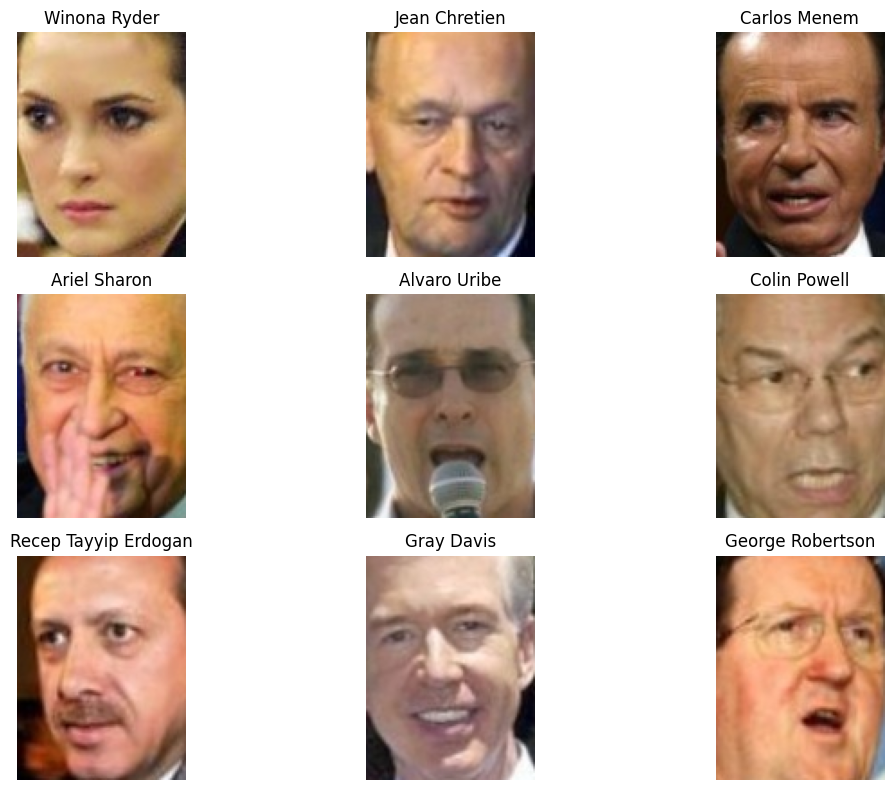

In [4]:
plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(lfw_dataset.images[i])
    plt.title(lfw_dataset.target_names[lfw_dataset.target[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Face Detection Using MTCNN

In [5]:
detector = MTCNN()

In [6]:
def extract_face(image):
    image = (image * 255).astype(np.uint8)

    results = detector.detect_faces(image)

    if len(results) == 0:
        return None

    x, y, width, height = results[0]["box"]

    x = max(0, x)
    y = max(0, y)

    face = image[y:y + height, x:x + width]

    if face.size == 0:
        return None

    return face

In [7]:
faces = []
face_labels = []

for image, label in zip(lfw_dataset.images, lfw_dataset.target):

    face = extract_face(image)

    if face is not None:
        faces.append(face)
        face_labels.append(label)

print("Total images:", len(lfw_dataset.images))
print("Faces detected:", len(faces))
print("Faces not detected:", len(lfw_dataset.images) - len(faces))

Total images: 3023
Faces detected: 2974
Faces not detected: 49


## 6. Extracting Facial Features Using EfficientNet Lite0

In [8]:
model_url = "https://tfhub.dev/tensorflow/efficientnet/lite0/feature-vector/2"

feature_extractor = hub.KerasLayer(
    model_url,
    input_shape=(224, 224, 3),
    trainable=False
)

In [9]:
processed_faces = []

for face in faces:
    face = cv2.resize(face, (224, 224))
    face = face.astype(np.float32) / 255.0
    processed_faces.append(face)

processed_faces = np.array(processed_faces)

print("Processed faces shape:", processed_faces.shape)

Processed faces shape: (2974, 224, 224, 3)


In [10]:
embeddings = []

batch_size = 16

for i in range(0, len(processed_faces), batch_size):

    batch = processed_faces[i:i + batch_size]

    batch_embeddings = feature_extractor(batch)

    embeddings.extend(batch_embeddings.numpy())

embeddings = np.array(embeddings)

print("Embeddings shape:", embeddings.shape)

Embeddings shape: (2974, 1280)


## 7. Encoding Face Labels

In [11]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(face_labels)

print("Encoded labels shape:", encoded_labels.shape)
print("Number of unique people:", len(label_encoder.classes_))

Encoded labels shape: (2974,)
Number of unique people: 62


## 8. Splitting the Dataset

In [12]:
indices = np.arange(len(embeddings))

X_train, X_test, y_train, y_test, train_indices, test_indices = train_test_split(
    embeddings,
    encoded_labels,
    indices,
    test_size=0.2,
    random_state=42,
    stratify=encoded_labels
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (2379, 1280)
Testing data shape: (595, 1280)
Training labels shape: (2379,)
Testing labels shape: (595,)


## 9. Training the SVM Classifier

In [13]:
svm_model = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

svm_model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


## 10. Evaluating the Model

In [14]:
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 73.61 %


## 11. Classification Report

In [15]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=[str(name) for name in label_encoder.classes_],
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.67      0.50      0.57         8
           1       1.00      0.71      0.83         7
           2       0.50      0.75      0.60         4
           3       0.75      0.43      0.55         7
           4       1.00      0.50      0.67         4
           5       0.92      0.75      0.83        16
           6       0.50      0.25      0.33         8
           7       1.00      1.00      1.00         5
           8       0.80      0.67      0.73         6
           9       0.50      0.25      0.33         4
          10       0.74      1.00      0.85        46
          11       0.43      0.50      0.46         6
          12       0.76      0.79      0.78        24
          13       0.50      0.25      0.33         4
          14       0.81      0.95      0.88       106
          15       0.53      0.77      0.63        22
          16       0.88      0.78      0.82         9
          17       0.50    

## 12. Confusion Matrix

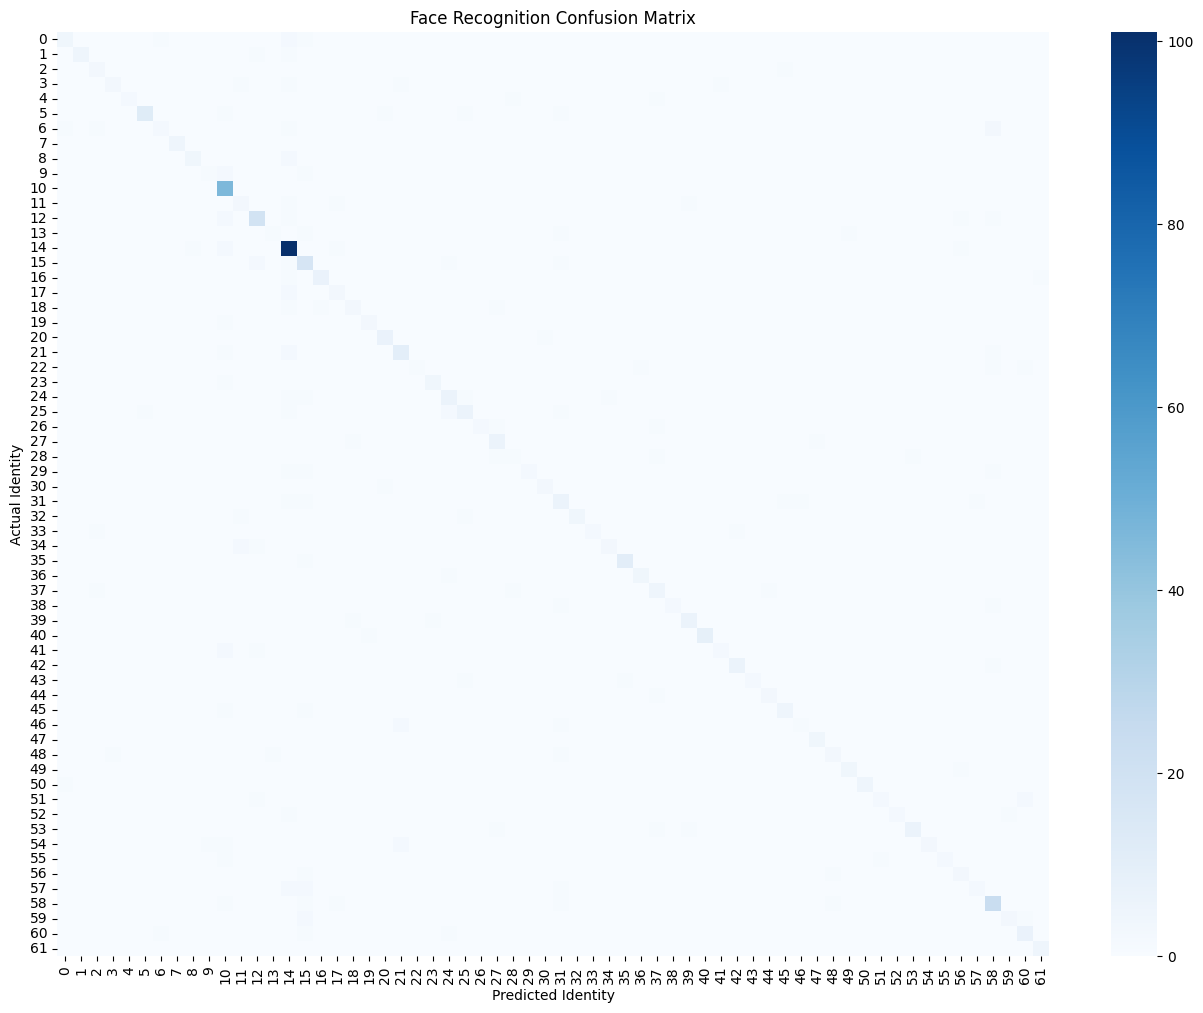

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Identity")
plt.ylabel("Actual Identity")
plt.title("Face Recognition Confusion Matrix")
plt.show()

## 13. Saving the Trained Model

In [17]:
with open("face_recognition_model.pkl", "wb") as file:
    pickle.dump(
        (svm_model, label_encoder),
        file
    )

print("Face recognition model saved successfully!")

Face recognition model saved successfully!


## 14. Loading the Saved Model

In [18]:
with open("face_recognition_model.pkl", "rb") as file:
    loaded_model, loaded_encoder = pickle.load(file)

print("Saved model loaded successfully!")

Saved model loaded successfully!


## 15. Testing the Loaded Model

In [19]:
loaded_predictions = loaded_model.predict(X_test)

loaded_accuracy = accuracy_score(y_test, loaded_predictions)

print("Loaded Model Accuracy:", round(loaded_accuracy * 100, 2), "%")

Loaded Model Accuracy: 73.61 %


## 16. Testing Face Recognition on a Sample

In [20]:
sample_prediction = loaded_model.predict(X_test[:1])[0]

actual_person = loaded_encoder.inverse_transform(
    [y_test[0]]
)[0]

predicted_person = loaded_encoder.inverse_transform(
    [sample_prediction]
)[0]

print("Actual Person:", actual_person)
print("Predicted Person:", predicted_person)

Actual Person: 14
Predicted Person: 14


## 17. Visualizing the Face Recognition Result

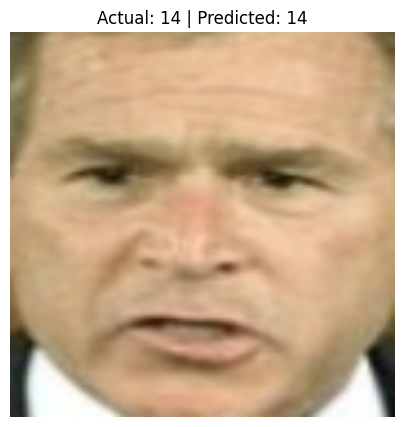

In [21]:
sample_index = 0

original_image_index = test_indices[sample_index]

plt.figure(figsize=(5, 5))

plt.imshow(processed_faces[original_image_index])

plt.title(f"Actual: {actual_person} | Predicted: {predicted_person}")
plt.axis("off")
plt.show()

## 18. Face Recognition Using a New Image

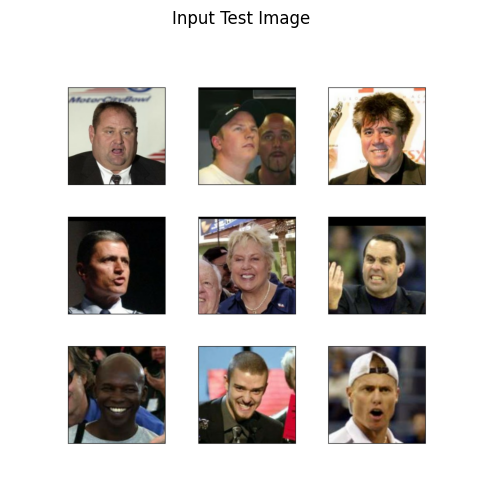

In [22]:
test_image_path = r"D:\english\lfw-0.1.1.png"

test_image = cv2.imread(test_image_path)

if test_image is None:
    raise FileNotFoundError("Test image not found. Check the image path.")

test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(test_image)
plt.title("Input Test Image")
plt.axis("off")
plt.show()

In [23]:
test_faces = detector.detect_faces(test_image)

print("Number of faces detected:", len(test_faces))


Number of faces detected: 11


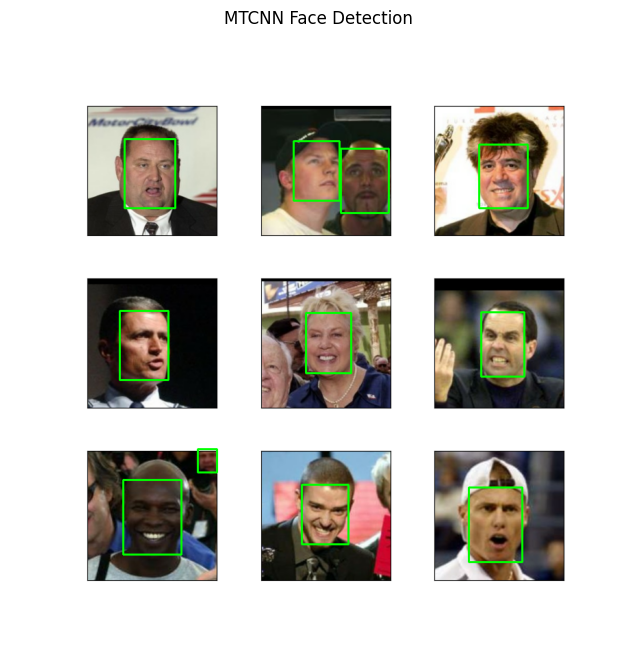

In [24]:
display_image = test_image.copy()

for face in test_faces:
    x, y, width, height = face["box"]

    x = max(0, x)
    y = max(0, y)

    cv2.rectangle(
        display_image,
        (x, y),
        (x + width, y + height),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 8))
plt.imshow(display_image)
plt.title("MTCNN Face Detection")
plt.axis("off")
plt.show()

In [25]:
new_faces = []

for face in test_faces:
    x, y, width, height = face["box"]

    x = max(0, x)
    y = max(0, y)

    cropped_face = test_image[
        y:y + height,
        x:x + width
    ]

    if cropped_face.size != 0:
        new_faces.append(cropped_face)

print("Extracted faces:", len(new_faces))

Extracted faces: 11


In [26]:
new_processed_faces = []

for face in new_faces:
    face = cv2.resize(face, (224, 224))
    face = face.astype(np.float32) / 255.0
    new_processed_faces.append(face)

new_processed_faces = np.array(new_processed_faces)

print("Processed faces shape:", new_processed_faces.shape)

Processed faces shape: (11, 224, 224, 3)


In [27]:
new_embeddings = feature_extractor(
    new_processed_faces,
    training=False
).numpy()

print("New embeddings shape:", new_embeddings.shape)

New embeddings shape: (11, 1280)


In [28]:
predicted_labels = loaded_model.predict(new_embeddings)

predicted_identities = loaded_encoder.inverse_transform(
    predicted_labels
)

for i, identity in enumerate(predicted_identities):
    print(f"Face {i + 1}: Predicted Identity = {identity}")

Face 1: Predicted Identity = 16
Face 2: Predicted Identity = 21
Face 3: Predicted Identity = 55
Face 4: Predicted Identity = 53
Face 5: Predicted Identity = 6
Face 6: Predicted Identity = 27
Face 7: Predicted Identity = 15
Face 8: Predicted Identity = 48
Face 9: Predicted Identity = 39
Face 10: Predicted Identity = 55
Face 11: Predicted Identity = 58


## 19. Visualizing Face Recognition Predictions

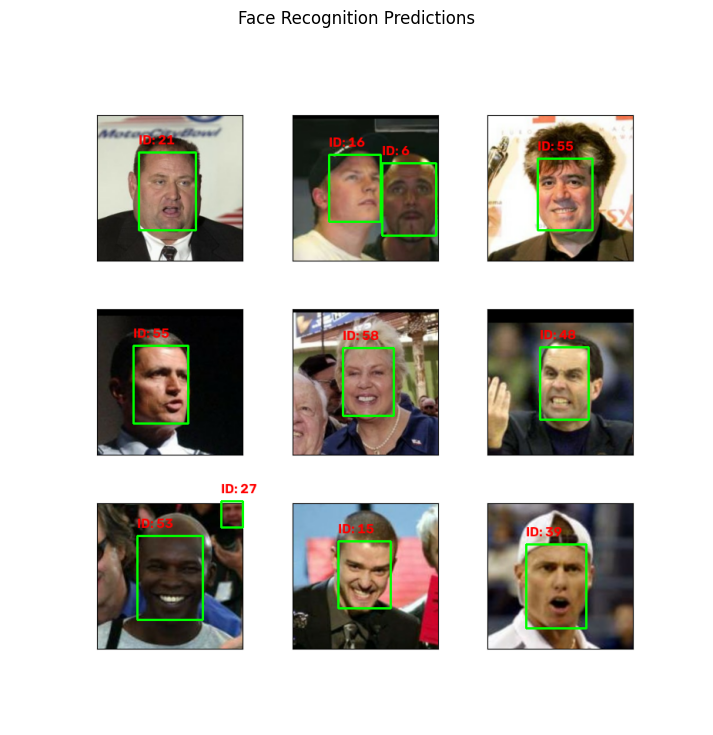

In [29]:
result_image = test_image.copy()

for face, identity in zip(test_faces, predicted_identities):

    x, y, width, height = face["box"]

    x = max(0, x)
    y = max(0, y)

    cv2.rectangle(
        result_image,
        (x, y),
        (x + width, y + height),
        (0, 255, 0),
        2
    )

    cv2.putText(
        result_image,
        f"ID: {identity}",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(12, 9))
plt.imshow(result_image)
plt.title("Face Recognition Predictions")
plt.axis("off")
plt.show()

## 20. Checking Prediction Confidence


In [30]:
prediction_probabilities = loaded_model.predict_proba(new_embeddings)

confidence_scores = np.max(prediction_probabilities, axis=1)

for i, confidence in enumerate(confidence_scores):
    print(f"Face {i + 1}: Confidence = {confidence * 100:.2f}%")

Face 1: Confidence = 56.02%
Face 2: Confidence = 13.47%
Face 3: Confidence = 5.54%
Face 4: Confidence = 32.56%
Face 5: Confidence = 6.81%
Face 6: Confidence = 24.13%
Face 7: Confidence = 6.34%
Face 8: Confidence = 10.53%
Face 9: Confidence = 44.54%
Face 10: Confidence = 7.01%
Face 11: Confidence = 15.59%


## 21. Filtering Uncertain Predictions

In [31]:
confidence_threshold = 0.50

for i, (identity, confidence) in enumerate(
    zip(predicted_identities, confidence_scores)
):

    if confidence >= confidence_threshold:
        print(f"Face {i + 1}: Candidate ID = {identity}")
    else:
        print(f"Face {i + 1}: Uncertain / Unknown")

Face 1: Candidate ID = 16
Face 2: Uncertain / Unknown
Face 3: Uncertain / Unknown
Face 4: Uncertain / Unknown
Face 5: Uncertain / Unknown
Face 6: Uncertain / Unknown
Face 7: Uncertain / Unknown
Face 8: Uncertain / Unknown
Face 9: Uncertain / Unknown
Face 10: Uncertain / Unknown
Face 11: Uncertain / Unknown


## 22. Project Summary and Conclusion

### Project Summary

This project demonstrates an educational face recognition system using the Labeled Faces in the Wild (LFW) dataset.

The system uses MTCNN for face detection, EfficientNet Lite0 for facial feature extraction, and Support Vector Machine (SVM) for identity classification.

### Technologies Used
- Python
- TensorFlow and TensorFlow Hub
- EfficientNet Lite0
- MTCNN
- OpenCV
- Scikit-learn
- NumPy
- Matplotlib and Seaborn

### Dataset Information
- Total original images: 3,023
- Number of identities: 62
- Successfully detected faces: 2,974
- Extracted facial features: 1,280 per face

### Model Performance
- SVM test accuracy: 73.61%
- Training/testing split: 80:20
- Test samples: 595

### Conclusion

The project successfully demonstrates face detection, facial feature extraction, identity classification, model evaluation, model persistence, and prediction on new images.

A basic confidence-based rejection mechanism was also implemented to flag uncertain predictions.

This is an educational prototype and not a production-ready authentication system. It does not implement liveness detection, anti-spoofing, or reliable unknown-person verification.